# Lab 09: ABC on a contaminated Hubble diagram

**ASTR 457, Fall 2026, posted Tue Nov 10, due Tue Nov 17 by noon (fork → PR, as always)**

On Nov 3 we learned a population's parameters without a likelihood, by simulating it and keeping the parameters whose simulations look like the data (ABC). Weyant et al. (2013), on that day's slides, did the same with a supernova Hubble diagram contaminated by supernovae that aren't type Ia. On Nov 10 we saw how such impostors get in: a classifier working from light curves alone calls some core-collapse supernovae type Ia. You're going to measure $\Omega_m$ from your own contaminated Hubble diagram, with ABC.

Put your notebook in `submissions/<your netid>/lab09.ipynb` - the data paths below are relative to that folder. It has to run top to bottom from a fresh kernel ("Restart & Run All").

Part 1 is 20%, Part 2 15%, Part 3 40%, Part 4 15%, and the AI-use appendix and verification plan 10%. Quote every number with its unit (if it has one), an error bar, and a sensible number of digits.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import pickle


NETID = 'acm18'   # <-- set this
LAB = '../../labs/09/data/'                              # from submissions/<your netid>/
d = pd.read_csv(LAB + f'{NETID}.csv')                    # columns: z, m_B, sigma_m
z, m, sig_m = d['z'].to_numpy(), d['m_B'].to_numpy(), d['sigma_m'].to_numpy()

## The survey

Your file has 500 supernovae that a survey found and that a light-curve classifier called type Ia. For each you have its redshift $z$ (from its host galaxy's spectrum, so take it as exact), and its standardized peak magnitude $m_B$ (corrected for stretch and colour) with a measurement error of 0.10 mag.

Here is how your sky was made. I generated it, so I know your true values.

- **Cosmology:** flat $\Lambda$CDM with $H_0 = 70$ km/s/Mpc, so the distance modulus is $\mu(z; \Omega_m) = 5 \log_{10}\left(d_L / 10\,{\rm pc}\right)$ with $d_L = (1+z)\,\frac{c}{H_0}\int_0^z \frac{dz'}{\sqrt{\Omega_m (1+z')^3 + 1 - \Omega_m}}$. Your $\Omega_m$ is unknown.
- **Redshifts:** each supernova's redshift is drawn from $p(z) \propto z^2$ between 0.01 and 0.7. (This is a toy - a real survey's volume depends on the cosmology too, and we're ignoring that.)
- **Type Ia:** standardized absolute magnitude $M \sim \mathcal{N}(-19.30, 0.12)$.
- **Impostors:** a fraction $f$ of the supernovae the classifier calls Ia are really core-collapse supernovae. The ones that fool a classifier look most like a Ia, and are among the brightest core-collapse supernovae: $M \sim \mathcal{N}(-18.5, 0.5)$. Your $f$ is unknown.
- **Measurement:** $m_B = M + \mu(z; \Omega_m) + \epsilon$, with $\epsilon \sim \mathcal{N}(0, 0.10)$.

Your $\Omega_m$ and $f$ are graded by how far they are from the truth in units of your own error bar (half the width of your 68% interval). Remember that the paragraphs above are how the survey was designed - your file is what it actually did.

## Part 1: Look first, then write the simulator (20%)

1. Plot your Hubble diagram ($m_B$ against $z$), and your Hubble residuals, $m_B - (-19.30) - \mu(z; 0.3)$, against $z$. Histogram $m_B$. Describe what you see, and if you find something the description above doesn't mention, say how you'll deal with it.
2. Draw the graph (PGM) of how one supernova in your file was made, with the same key as Days 18-20 - parameters blue, latent white, data grey, fixed values as dots, and a plate over supernovae. Which quantities are latent? Where does $f$ enter?
3. Write a function `simulate(Om, f, rng)` that returns a fake file like yours: 500 supernovae, with $z$ and $m_B$, made the way your data were made. Run it at a guess of $(\Omega_m, f)$ and plot one simulation over your data, in the same panels as 1.1.

#### Hints:
- `astropy.cosmology.FlatLambdaCDM(H0=70, Om0=...).distmod(z)` is correct, but far too slow to call 50,000 times. Tabulate $\mu(z; \Omega_m)$ once, on a grid of $z$ and $\Omega_m$ (spacing 0.005 in $\Omega_m$ is plenty), and interpolate. Check your table against astropy at a few points.
- Your simulator will be called tens of thousands of times. Draw everything for one dataset in a few vectorized `numpy` calls, not a Python loop over supernovae.

Text(0, 0.5, 'H_resid')

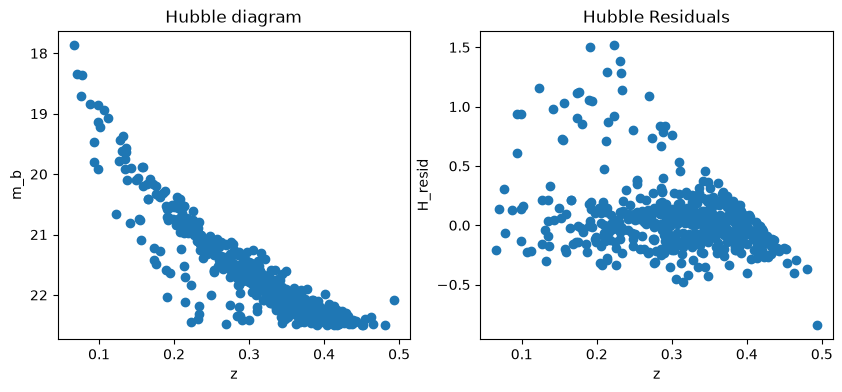

In [2]:
# Part 1: your work here
from astropy.cosmology import FlatLambdaCDM
cosmo = FlatLambdaCDM(H0 = 70, Om0 = 0.3)
mu_vals = cosmo.distmod(z).value

H_resid = m - (-19.3) - mu_vals
fig, (ax1,ax2) = plt.subplots(1,2, figsize = (10,4))
ax1.scatter(z,m)
ax1.set_title('Hubble diagram')
ax1.set_xlabel('z')
ax1.set_ylabel('m_b')
ax1.invert_yaxis()

ax2.scatter(z,H_resid)
ax2.set_title('Hubble Residuals')
ax2.set_xlabel('z')
ax2.set_ylabel('H_resid')

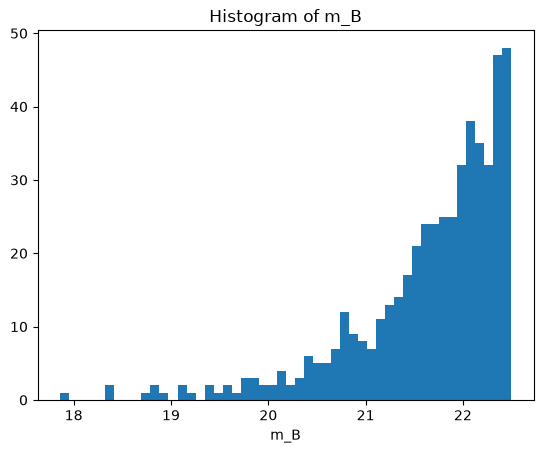

1


In [3]:
plt.hist(m, bins = 50)
plt.title("Histogram of m_B");plt.xlabel('m_B')
plt.show()
print(np.count_nonzero(m == m.max()))

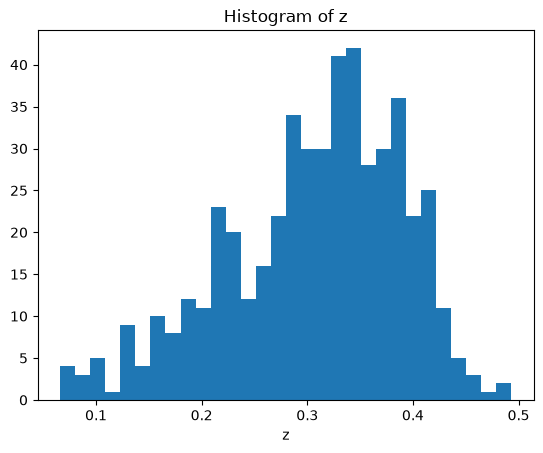

In [4]:
plt.hist(z, bins = 30)
plt.title("Histogram of z");plt.xlabel('z')
plt.show()

In the hubble diagram I can see a trend in decreasing magnitude with redshift, which is what the simulation expected. Along with a secondary population that looks fainter than the main trend. Interestingly the residuals form a wedge with increasing redshift, according to the survey, the hubble residual should just show $\epsilon$ and it should be a gaussian distribution centered around 0. The spread father from 0 I can atribute to the contamination supernovae, the diagonal cutoff looks like selection bias where faint supernovae are not observed at a high redshift. After comparing the histograms for both magnitude and redshift I can confirm that this effect is an upper limit on what magnitudes can be seen. I will take this limit into account when simulating a survey by having the faint surpernovae replaced by a new randomly generated one until magnitude is <= my current maximum value.

#### 1.2

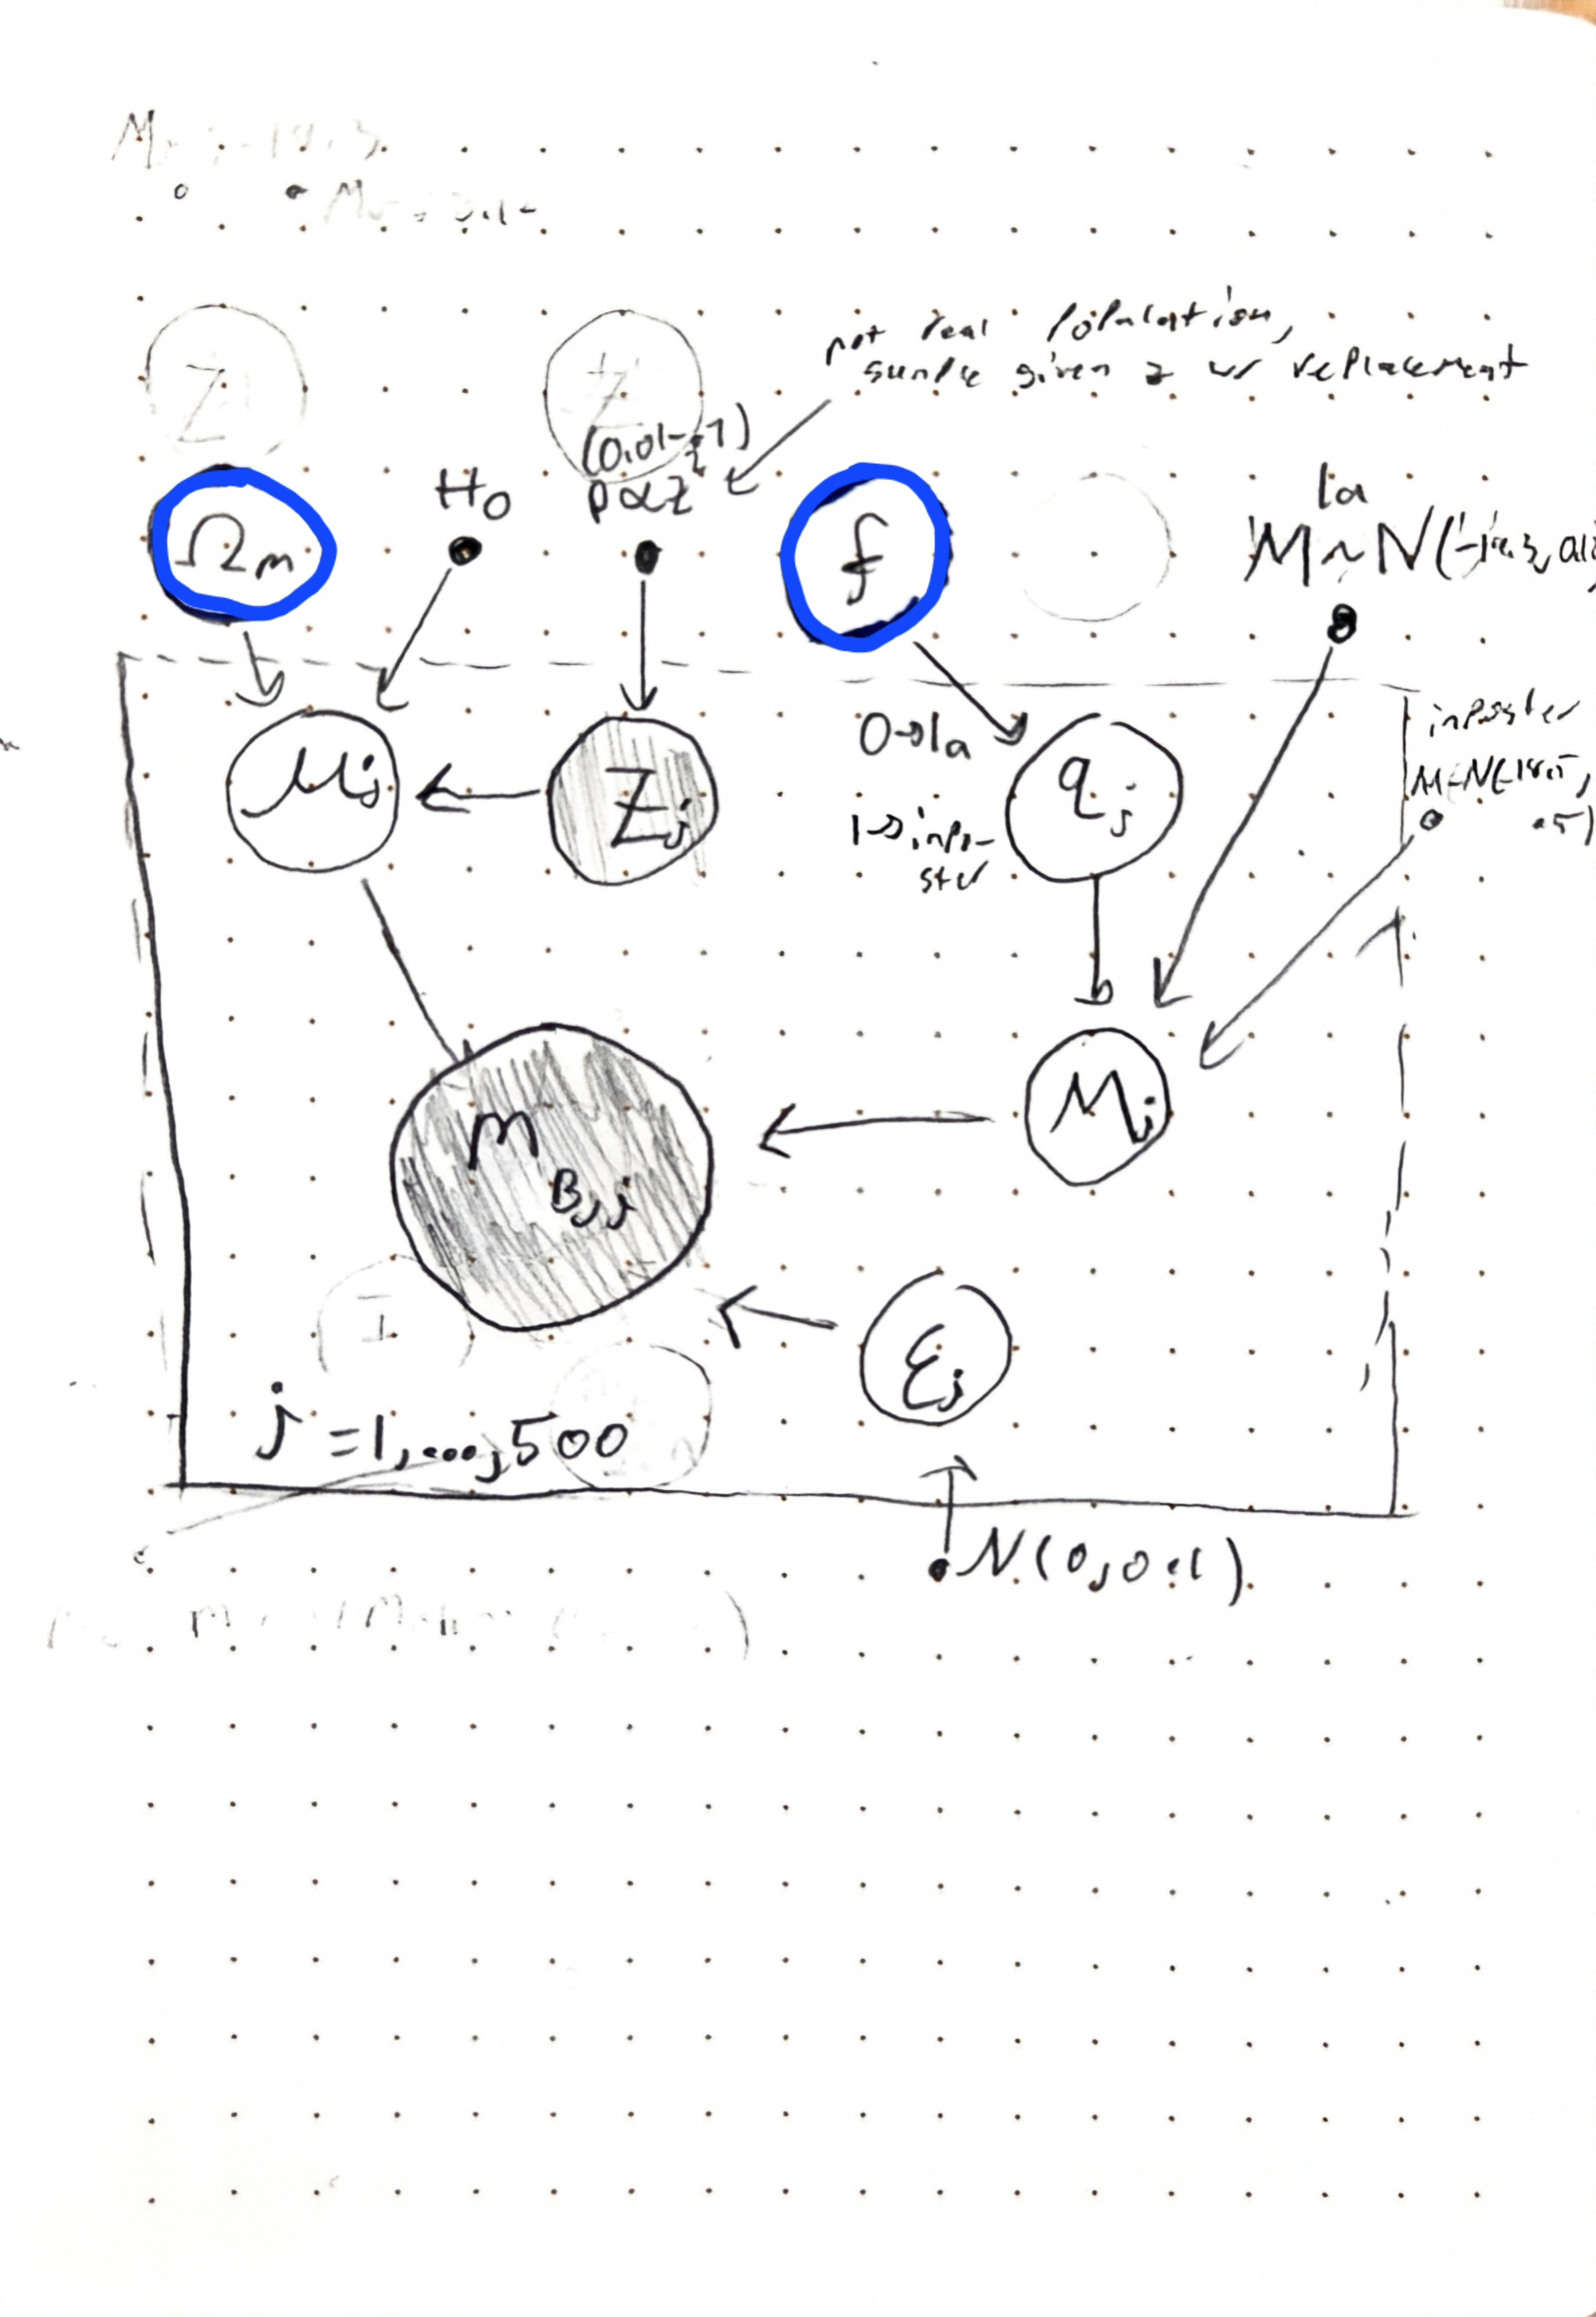

The latent quantaties are the distance modulus (determined by z and $\Omega_m$, the absolute magnitude, epsilon measurment error and $q_i$ (if a supernova is 1a or an imposter). $f$ is the fitted parameter that determines how much of $q_j$ is 0 and how much is 1.

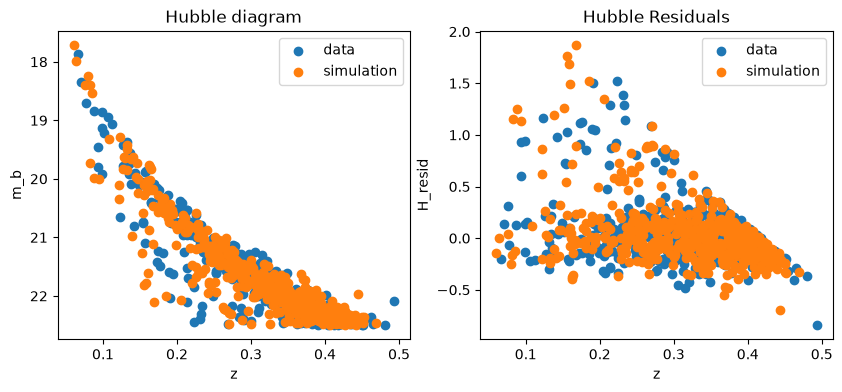

In [5]:

from scipy.interpolate import interp1d

def make_distance_modulus(Om):
    """
    Precompute a distance modulus table and
    return a fast interpolating function.
    """
    # cosmology
    cosmo = FlatLambdaCDM(H0=70, Om0=Om)

    # grid in z
    z_grid = np.arange(0.01, 1.505, 0.005)

    # expensive call done once
    mu_grid = cosmo.distmod(z_grid).value

    # interpolation function
    return interp1d(
        z_grid,
        mu_grid,
        kind='linear',
        bounds_error=False,
        fill_value='extrapolate'
    )

def simulate(Om, f, rng):
    N, m_cutoff = 500, np.max(m)
    distance_modulus = make_distance_modulus(Om)
    detected = []

    while sum(len(x) for x in detected) < N:
        n = N - sum(len(x) for x in detected)

        # Draw candidate redshifts from p(z) proportional to z^2
        u = rng.uniform(0, 1, n)
        zs = (0.01**3 + u * (0.7**3 - 0.01**3))**(1/3)

        # Draw supernova type and absolute magnitude
        q = rng.binomial(1, f, n)
        M = np.empty(n)
        M[q == 0] = rng.normal(-19.3, 0.12, np.sum(q == 0))
        M[q == 1] = rng.normal(-18.5, 0.50, np.sum(q == 1))

        # Generate apparent magnitudes
        mu = distance_modulus(zs)
        mB = mu + M + rng.normal(0, 0.1, n)

        # Keep detected objects; rejected objects are replaced next iteration
        keep = mB <= m_cutoff
        detected.append(pd.DataFrame({
            "z": zs[keep],
            "mB": mB[keep],
            "mu": mu[keep]
        }))

    return pd.concat(detected, ignore_index=True).iloc[:N]
rng = np.random.default_rng(6)

sdf = simulate(0.3,.3,rng)

sH_resid = sdf['mB'] - (-19.3) - sdf['mu']
fig, (ax1,ax2) = plt.subplots(1,2, figsize = (10,4))
ax1.scatter(z,m, label = 'data')
ax1.scatter(sdf['z'],sdf['mB'], label = 'simulation')
ax1.set_title('Hubble diagram')
ax1.set_xlabel('z')
ax1.set_ylabel('m_b')
ax1.legend()
ax1.invert_yaxis()

ax2.scatter(z,H_resid, label = 'data')
ax2.scatter(sdf['z'],sH_resid, label = 'simulation')
ax2.set_title('Hubble Residuals')
ax2.set_xlabel('z')
ax2.set_ylabel('H_resid')
ax2.legend()

In [6]:
Om = 0.3

dm = make_distance_modulus(Om)
cosmo = FlatLambdaCDM(H0=70, Om0=Om)

for zv in [0.05, 0.25, 0.8, 1.2, .38]:
    print(
        zv,
        cosmo.distmod(zv).value,
        dm(zv),
        dm(zv) - cosmo.distmod(zv).value
    )

0.05 36.73459039451254 36.73459039451254 0.0
0.25 40.50215473370677 40.50215473370677 0.0
0.8 43.50256928302412 43.50256928302412 0.0
1.2 44.59003340139067 44.59003340139067 0.0
0.38 41.55325716319324 41.55325716319324 0.0


**ANSWER (what you see in the data, your graph, and what your simulator does):**



## Part 2: The fit you'd do without thinking (15%)

1. Pretend every supernova in your file is a type Ia. Fit $\Omega_m$ by minimizing $\chi^2 = \sum_i [m_{B,i} - (-19.30) - \mu(z_i; \Omega_m)]^2 / \sigma_{\rm tot}^2$, with $\sigma_{\rm tot}^2 = 0.12^2 + 0.10^2$, and report $\hat\Omega_m$ with its $1\sigma$ error from $\Delta\chi^2 = 1$.
2. Which way should the impostors push this fit, and why? Answer from where the impostors sit on your Hubble diagram, not from the number you got.

In [7]:
# Part 2: your work here
from scipy.optimize import minimize

def chi2(theta,z,mB):
    Om = theta[0]
    if Om < 0:
        return np.inf
    distance_modulus = make_distance_modulus(Om)
    mu = distance_modulus(z)
    sigma_tot2 = 0.12**2 + 0.10**2
    return np.sum((mB + 19.3 - mu)**2 / sigma_tot2)
theta0 = [.3]
result = minimize(chi2, theta0, args=(z,m), method='Nelder-Mead')
result.x

array([0.24832031])

In [8]:
Om_hat = result.x[0]
chi2_min = chi2([Om_hat], z, m)

Oms = np.linspace(0.01, 1.0, 5000)
chi2_vals = np.array([chi2([Om], z, m) for Om in Oms])

mask = chi2_vals <= chi2_min + 1

Om_lo = Oms[mask].min()
Om_hi = Oms[mask].max()

print(f"Ωm = {Om_hat:.3f} +{Om_hi-Om_hat:.3f} -{Om_hat-Om_lo:.3f}")

Ωm = 0.248 +0.013 -0.013


In [9]:
odf = simulate(0.3,0,rng)

sresult = minimize(chi2, theta0, args=(sdf['z'],sdf['mB']), method='Nelder-Mead')
oresult = minimize(chi2, theta0, args=(odf['z'],odf['mB']), method='Nelder-Mead')
print(sresult.x, oresult.x)

[0.27457031] [0.37353516]


**ANSWER (the naive fit, then why the impostors push it the way they do):**

$\Omega_m = 0.248 \pm 0.013$

The imposters in the data set have biased this value to be smaller than the truth. According to my simulation, the imposter novae appear fainter than the 1a and the only way that the minimization model can acocunt for that brightness is to change the distance modulus. z is fixed, therefore making $\Omega_m$ smaller is the only way to increase $\mu$ to account for the extra brightness.  

## Part 3: ABC (40%)

1. **Summaries.** Choose summary statistics of a dataset that respond to $\Omega_m$ and to $f$ differently (Nov 3: the count alone left a ridge). For each, say which parameter you expect it to track and why. Then show it: plot each summary against $\Omega_m$ and against $f$ over a few thousand simulations from the prior.
2. **Rejection ABC.** Use flat priors, $\Omega_m \in [0.05, 0.7]$ and $f \in [0, 0.5]$. Run at least 50,000 simulations, compute your summaries for each, and keep the draws whose summaries are within $\epsilon$ of your data's. Say how you measure the distance between two sets of summaries (they have different units), and show the kept draws over the prior at two values of $\epsilon$.
3. Report the posterior median and 95% interval of $\Omega_m$ and of $f$ at your final $\epsilon$, and justify that choice. Compare $\Omega_m$ with your Part 2 fit.

#### Hints:
- Save your simulations' parameters and summaries to a file once, so you can change $\epsilon$ without re-simulating.
- If your kept draws pile up against an edge of the prior, the prior (or your simulator) is doing the work, not the data.

# Part 3: your work here



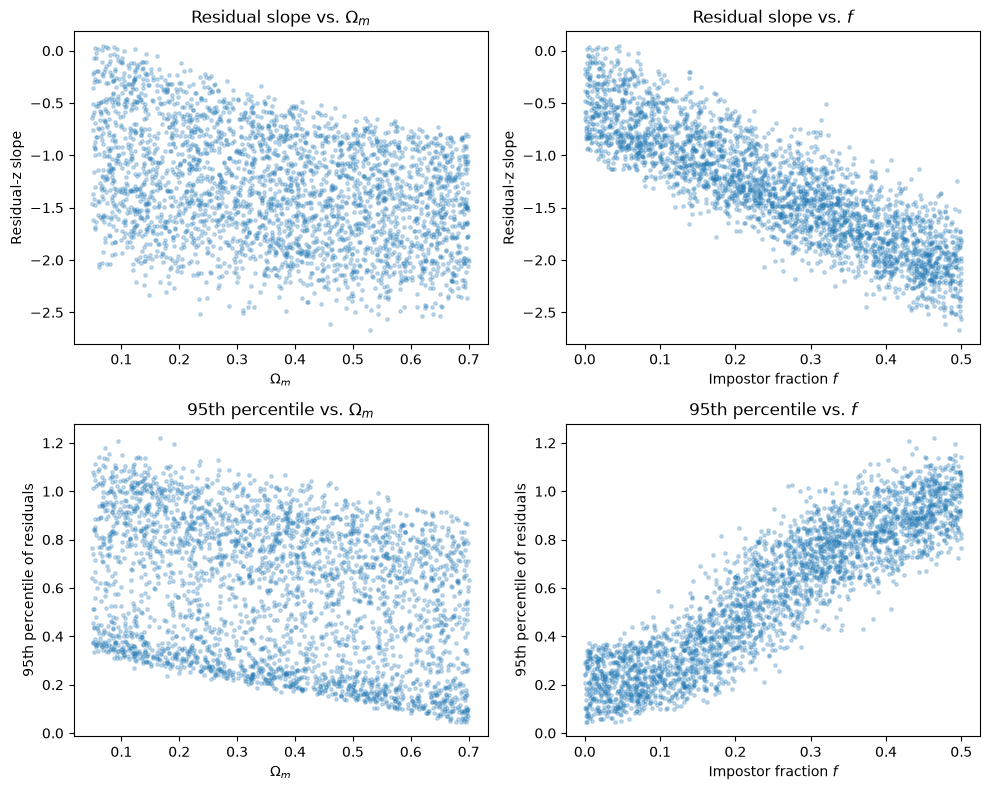

In [10]:
nsamp, Om_ref = 3000, 0.3

Oms = rng.uniform(0.05, 0.7, nsamp)
fs  = rng.uniform(0.0, 0.5, nsamp)
slope, p95_resid = np.empty(nsamp), np.empty(nsamp)

mu_ref = make_distance_modulus(Om_ref)

for i, (Om, f) in enumerate(zip(Oms, fs)):
    df = simulate(Om, f, rng)
    resid = df["mB"].to_numpy() + 19.3 - mu_ref(df["z"].to_numpy())
    slope[i] = np.polyfit(df['z'], resid, 1)[0]
    p95_resid[i] = np.percentile(resid, 95)

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

# Residual slope against both parameters
axes[0, 0].scatter(Oms, slope, s=6, alpha=0.25)
axes[0, 0].set(
    xlabel=r"$\Omega_m$",
    ylabel="Residual-z slope",
    title=r"Residual slope vs. $\Omega_m$"
)

axes[0, 1].scatter(fs, slope, s=6, alpha=0.25)
axes[0, 1].set(
    xlabel="Impostor fraction $f$",
    ylabel="Residual-z slope",
    title=r"Residual slope vs. $f$"
)

# Residual 95th percentile against both parameters
axes[1, 0].scatter(Oms, p95_resid, s=6, alpha=0.25)
axes[1, 0].set(
    xlabel=r"$\Omega_m$",
    ylabel="95th percentile of residuals",
    title=r"95th percentile vs. $\Omega_m$"
)

axes[1, 1].scatter(fs, p95_resid, s=6, alpha=0.25)
axes[1, 1].set(
    xlabel="Impostor fraction $f$",
    ylabel="95th percentile of residuals",
    title=r"95th percentile vs. $f$"
)

plt.tight_layout()
plt.show()

In [11]:
'''Only run simulaition once and then pickle it'''
# nsamp, Om_ref = 50000, 0.3

# Oms = rng.uniform(0.05, 0.70, nsamp)
# fs  = rng.uniform(0.00, 0.50, nsamp)
# mu_ref = make_distance_modulus(Om_ref)
# rows = np.empty((nsamp, 4))

# for i, (Om, f) in enumerate(zip(Oms, fs)):
#     df = simulate(Om, f, rng)
#     zsim = df["z"].to_numpy()
#     resid = df["mB"].to_numpy() + 19.3 - mu_ref(zsim)
#     rows[i] = Om, f, np.polyfit(zsim, resid, 1)[0], np.percentile(resid, 95)

# summary_df = pd.DataFrame(
#     rows, columns=["Om", "f", "resid_slope", "resid_p95"]
# )

# summary_df
# with open("lab09ABC.pkl", "wb") as file:
#     pickle.dump(summary_df, file)

'Only run simulaition once and then pickle it'

In [12]:
with open("lab09ABC.pkl", "rb") as file:
    ABCdf = pickle.load(file)

In [13]:
ABCdf

,Om,f,resid_slope,resid_p95
0,0.235123,0.170069,-0.755692,0.503228
1,0.225781,0.068577,-0.395763,0.299769
2,0.120955,0.454234,-1.484567,0.872189
3,0.091297,0.464696,-1.758321,1.040429
4,0.537714,0.005308,-0.605369,0.115869
...,...,...,...,...
49995,0.647503,0.008696,-0.820123,0.071666
49996,0.651070,0.483422,-2.385040,0.819251
49997,0.504433,0.072955,-0.890485,0.182256
49998,0.098851,0.072128,-0.366311,0.356506


In [14]:
# Observed summaries, using the same reference cosmology as ABCdf
obs_resid = m + 19.3 - mu_ref(z)
obs_summary = np.array([
    np.polyfit(z, obs_resid, 1)[0],
    np.percentile(obs_resid, 95)
])

# Standardized distance from each simulation to the observed summaries
cols = ["resid_slope", "resid_p95"]
S = ABCdf[cols].to_numpy()
scale = S.std(axis=0)

ABCdf["distance"] = np.sqrt(np.sum(((S - obs_summary) / scale)**2, axis=1))

# Accept the closest 1% of the 50,000 simulations
epsilon1 = ABCdf["distance"].quantile(0.01)
accepted1 = ABCdf[ABCdf["distance"] <= epsilon1].copy()

# Accept the closest 5% of the 50,000 simulations
epsilon2 = ABCdf["distance"].quantile(0.05)
accepted2 = ABCdf[ABCdf["distance"] <= epsilon2].copy()




Accepted fraction: 2.0%
epsilon: 0.2464, N accepted: 1000
Om = 0.207 +0.157 -0.135
f  = 0.280 +0.097 -0.080

Accepted fraction: 1.0%
epsilon: 0.1749, N accepted: 500
Om = 0.207 +0.151 -0.128
f  = 0.277 +0.097 -0.079

Accepted fraction: 0.5%
epsilon: 0.1227, N accepted: 250
Om = 0.202 +0.118 -0.123
f  = 0.279 +0.097 -0.081


Text(0, 0.5, 'f')

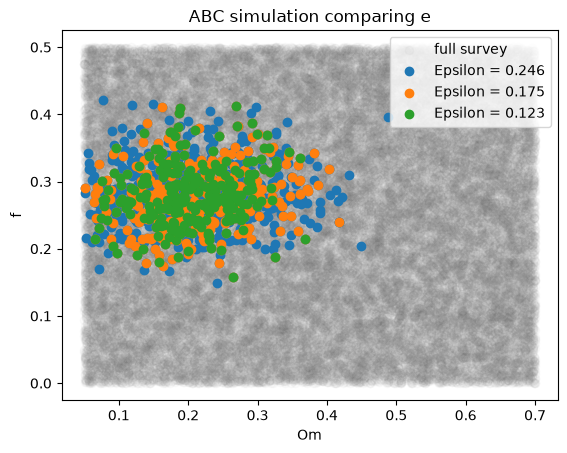

In [15]:
plt.scatter(ABCdf['Om'],ABCdf['f'], label = 'full survey', alpha = .03, c = 'grey')
for frac in [0.02, 0.01, 0.005]:
    eps = ABCdf["distance"].quantile(frac)
    acc = ABCdf[ABCdf["distance"] <= eps]
    q = acc[["Om", "f"]].quantile([0.025, 0.50, 0.975])

    plt.scatter(acc['Om'],acc['f'], label = f'Epsilon = {eps:.3}')
    
    print(f"\nAccepted fraction: {frac:.1%}")
    print(f"epsilon: {eps:.4f}, N accepted: {len(acc)}")
    print(f"Om = {q.loc[0.50,'Om']:.3f} "
          f"+{q.loc[0.975,'Om']-q.loc[0.50,'Om']:.3f} "
          f"-{q.loc[0.50,'Om']-q.loc[0.025,'Om']:.3f}")
    print(f"f  = {q.loc[0.50,'f']:.3f} "
          f"+{q.loc[0.975,'f']-q.loc[0.50,'f']:.3f} "
          f"-{q.loc[0.50,'f']-q.loc[0.025,'f']:.3f}")
plt.legend()
plt.title('ABC simulation comparing e');plt.xlabel('Om');plt.ylabel('f')

**ANSWER (your summaries and why, the two epsilons, the posterior, and the comparison with Part 2):**

The two summary statistics I am chosing is the slope between hubble residuals and redshift to isolate effects of $\Omega_m$, and the 95th percitile point of the hubble residual to isolate the effects of $f$. When $\Omega_m$ is too small the distance gets over predicted at high z, the inverse effect takes place for large $\Omega_m$. $f$ adds positive outliers to the residuals accross redshift and does not considerably effect the slope. The 95th percitile point for the hubble residuals will be effected considerably from the high outliers created by the imposter novae but should not be effected too much by $\Omega_m$ which will primarily move the median.

I decided to check 3 $\epsilon$s that I choose based on how much of the data they kept. After looking at their descripitve stats and my comparison plot I decided to choose $\epsilon$ = 0.175 which coorelates to accepting the closes 1% of ABC data to my origional dataset. This selection looks to have a non noisy distribution around without too much spread when compared to both a .5%, and 2% accepted fraction. To compute the distance I took scalled each value by subtracting the observed value and dividing by the erorr, then I set the square root of the summed squares to be the distance in (slope, percentile) space. 

This process gave me the final values of: **$\Omega_M$ = 0.207 + 0.151 - 0.128 d, $f$ = 0.277 +0.97 -0.079**

The posterior value for $\Omega_m$ proved to be smaller than the naive fit.

## Part 4: Check it (15%)

1. **Posterior predictive check.** For 100 of your kept draws, simulate a new dataset. Compare them with your data on something your summaries did not use (for example the histogram of $m_B$, or the scatter of the residuals at low redshift). Do your data look like a typical simulation?
2. **Coverage.** Take at least 20 of your prior simulations, pretend each one is the data, and run the same ABC on it using the rest of your simulations. How often does your 95% interval contain the true $\Omega_m$, and the true $f$? (Nov 3: a 95% interval should hold the truth 95% of the time.)
3. **What does your simulator assume?** Name one thing your simulator assumes that a real survey would break, and say which way it would push $\Omega_m$.

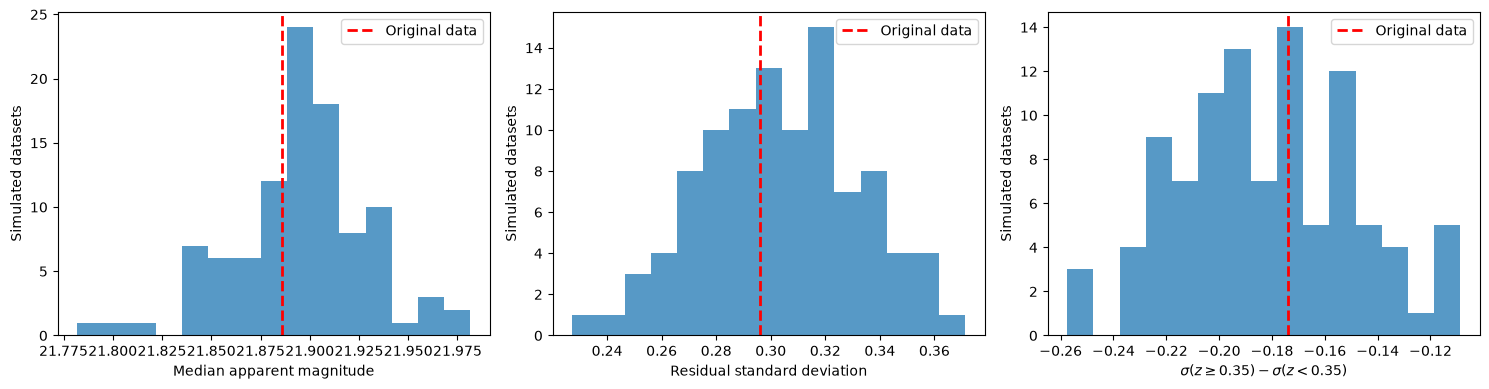

epsilon = 0.1749, accepted draws = 500
Median apparent magnitude: observed=21.886, PPC percentile=29.0%
Residual standard deviation: observed=0.296, PPC percentile=38.0%
$\sigma(z \geq 0.35)-\sigma(z < 0.35)$: observed=-0.174, PPC percentile=62.0%


In [16]:
# Part 4: your work here
rng_ppc = np.random.default_rng(457)
mu_ref = make_distance_modulus(0.3)

# Keep draws accepted using the 1% ABC tolerance
epsilon = ABCdf["distance"].quantile(0.01)
accepted = ABCdf[ABCdf["distance"] <= epsilon]
draws = accepted.sample(n=100, replace=False, random_state=457)

def ppc_stats(zs, mB):
    zs, mB = np.asarray(zs), np.asarray(mB)
    resid = mB + 19.3 - mu_ref(zs)

    low = resid[zs < 0.35]
    high = resid[zs >= 0.35]

    return [
        np.median(mB),
        np.std(resid),
        np.std(high) - np.std(low)
    ]

# Statistics from the original data
obs_stats = np.array(ppc_stats(z, m))

# Statistics from 100 new posterior-predictive datasets
ppc = np.empty((100, 3))

for i, (_, draw) in enumerate(draws.iterrows()):
    df = simulate(draw["Om"], draw["f"], rng_ppc)
    ppc[i] = ppc_stats(df["z"], df["mB"])

labels = [
    "Median apparent magnitude",
    "Residual standard deviation",
    r"$\sigma(z \geq 0.35)-\sigma(z < 0.35)$"
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for j, ax in enumerate(axes):
    ax.hist(ppc[:, j], bins=15, alpha=0.75)
    ax.axvline(obs_stats[j], color="red", ls="--", lw=2,
               label="Original data")
    ax.set_xlabel(labels[j])
    ax.set_ylabel("Simulated datasets")
    ax.legend()

plt.tight_layout()
plt.show()

print(f"epsilon = {epsilon:.4f}, accepted draws = {len(accepted)}")
for j, label in enumerate(labels):
    pct = 100 * np.mean(ppc[:, j] <= obs_stats[j])
    print(f"{label}: observed={obs_stats[j]:.3f}, PPC percentile={pct:.1f}%")

Based on these histograms my data seems to be pretty typical data within the posterior.

In [17]:
rng_cov = np.random.default_rng(457)
cols = ["resid_slope", "resid_p95"]
test_idx = rng_cov.choice(ABCdf.index, size=20, replace=False)
coverage = []

for idx in test_idx:
    truth = ABCdf.loc[idx]
    reference = ABCdf.drop(index=idx)
    
    S = reference[cols].to_numpy()
    pseudo_obs = truth[cols].to_numpy(dtype=float)
    scale = S.std(axis=0, ddof=1)

    distance = np.sqrt(np.sum(((S - pseudo_obs) / scale)**2, axis=1))
    epsilon = np.quantile(distance, 0.01)
    accepted = reference.loc[distance <= epsilon]

    q = accepted[["Om", "f"]].quantile([0.025, 0.975])
    Om_covered = q.loc[0.025, "Om"] <= truth["Om"] <= q.loc[0.975, "Om"]
    f_covered  = q.loc[0.025, "f"]  <= truth["f"]  <= q.loc[0.975, "f"]

    coverage.append([idx, truth["Om"], truth["f"], epsilon,
                     len(accepted), Om_covered, f_covered])

coverage_df = pd.DataFrame(
    coverage,
    columns=["index", "true_Om", "true_f", "epsilon",
             "n_accepted", "Om_covered", "f_covered"]
)

print(f"Omega_m 95% coverage: {coverage_df['Om_covered'].mean():.1%} "
      f"({coverage_df['Om_covered'].sum()}/20)")
print(f"f 95% coverage:       {coverage_df['f_covered'].mean():.1%} "
      f"({coverage_df['f_covered'].sum()}/20)")


Omega_m 95% coverage: 100.0% (20/20)
f 95% coverage:       95.0% (19/20)


The coverage test went exactly as I would expect for such a small dataset

**ANSWER (the check, the coverage, and the assumption):**

My simulator assumes that the survey has a sharp and spatially constant limiting magnitude. By setting every object with $m_B$ <= $m_cutoff$ to be detected and fainter objects missed. A real survey would have an efficiency that decreases gradually near a lmiting magnitude that varies with observing conditions. 

## Part 5: AI-use appendix and verification plan (10%)

1. **AI use**: which tools, for what, what they got wrong, and how you caught it. "I didn't use any" is fine if true.
2. **Reflection**: what would have gone wrong in your answer if you had not checked the AI's output? Name the specific thing.
3. **Verification plan**: the checks you ran before trusting your Part 3 numbers, and what failure would have looked like for each. Part 4.2 is already one. Another to consider: simulate a dataset at an $(\Omega_m, f)$ you choose, run your whole ABC on it, and see whether you get back what you put in.

**AI-USE APPENDIX:**

I used an agent in microsoft co pilot to help write the code for this project. One thing that copilot had trouble with is identifying what effect caused the wedging in the hubble residuals. It had me try some far out solutions until I ended up asking it to test for a magnitude limit which ended providing the intended results. The first recomendation given was to just ignore the effect and continue on

**REFLECTION:**

If I had trusted the AI's instinct on effects in the dataset not in the prompt I would have missed the high magnitude limit on observations. This would have had a spiraling effect that would cause my ABC simulation to be wrong. 

**VERIFICATION PLAN:**

The first verification check I did was to look at the distribution of mB and z to see if there was any sampling bias present. Falure looked like a gaussian histogram cut off on the positive side, I did see this so I had to incorperate the selection effect into my simulation.
Another verification was plotting my simulated data on top of the real data to make sure I retain the proper information and shape, failure would be if the simulated data did not match the provided data. In part 3, along with checking my summary statistics against the paramater I chose them for, I also compared the summary statistics to the other parameter. Failure would be if there was structure in both variables. I did not find any extra structure in the unintended variable so I decided to stick to my chosen statistics